In [10]:
# median fill missing values columns

import pandas as pd 
import numpy as np 

X_train = pd.read_csv("X_train.csv", index_col="id")
y_train = pd.read_csv("y_train.csv", index_col="id")["y"]

# median of each column
train_medians = X_train.median()

# new filled table
X_train_med = X_train.fillna(train_medians)


# check
print("NaNs left:", X_train_med.isna().sum().sum())
print(f"Shape: {X_train_med.shape}")

X_train_med

NaNs left: 0
Shape: (1212, 832)


,x0,x1,x2,x3,x4,x5,x6,x7,x8,x9,...,x822,x823,x824,x825,x826,x827,x828,x829,x830,x831
id,,,,,,,,,,,,,,,,,,,,,
0.0,14168.823171,10514.380717,3316.149698,94230.695124,102.386606,92.677127,11108.748199,10866.505510,10837.622093,10.227734,...,10064.750764,12352.094085,846.014651,105.132144,102.112809,2090.004260,2.691845,1234.374109,1000.784475,9285.751272
1.0,17757.037554,10839.483074,4101.016273,92959.527633,105.029940,99.855168,10013.959449,10826.607494,10076.101597,11.436970,...,10064.750764,16198.071494,776.084467,106.385590,103.472030,2474.051881,2.287976,1362.350726,1012.626705,11750.284764
2.0,14226.656663,11029.642499,3401.539562,124055.600561,100.542483,92.860892,9991.006638,10492.342868,10494.225267,10.810076,...,10329.704431,13976.063780,737.040332,103.671234,109.458246,2656.083281,2.843706,888.353607,1048.810385,9553.922728
3.0,8766.012436,7384.202998,2147.308418,100157.719990,104.855061,101.929026,10050.049932,10499.521099,10525.030989,10.092109,...,10008.251395,6212.127347,329.044233,105.084488,104.858546,1097.785204,2.732257,927.752967,1048.357330,9981.210986
4.0,13801.016418,13269.493652,3408.316953,92048.527786,103.759758,95.789235,9667.353978,10750.783106,10618.800750,12.006773,...,10095.782015,13772.061493,792.045039,104.969600,100.369834,2693.053231,2.702908,1471.354073,1071.284484,9423.533063
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1207.0,18707.457475,13610.725702,3785.886941,113497.632841,109.526764,97.812339,11274.011935,10803.953566,10949.811419,9.970521,...,8472.132451,17727.003274,1033.057071,104.838553,102.235191,3099.069091,3.079234,1362.889974,1053.778881,10110.360570
1208.0,17108.239122,12168.536128,3442.619145,98218.773311,100.468476,109.994258,11031.326117,10231.743317,10687.321177,10.238957,...,8839.251924,14721.087037,792.061138,105.823015,109.915094,3124.059793,2.935047,1577.404870,1026.749434,10620.330033
1209.0,14264.707321,9273.405761,3580.894003,101668.927699,102.620705,104.470375,9159.594864,10661.827392,10623.176915,10.132906,...,10264.321725,15226.056342,831.025190,101.926717,101.669153,2252.031870,2.710103,1781.799720,1066.379647,10317.757445


In [ ]:
# Check & Drop constant columns 

n_unique = X_train_med.nunique()
constant_cols = n_unique[n_unique <= 1].index

print(n_unique.describe())                      # min / median / max unique values per column 
print("constant columns:", constant_cols)

X_train     = X_train.drop(columns=constant_cols)
X_train_med = X_train_med.drop(columns=constant_cols)

count     832.000000
mean     1113.890625
std        81.378578
min         1.000000
25%      1113.000000
50%      1119.000000
75%      1125.000000
max      1147.000000
dtype: float64
constant columns: Index(['x104', 'x129', 'x489', 'x530'], dtype='str')


outliers found: 25 of 1212


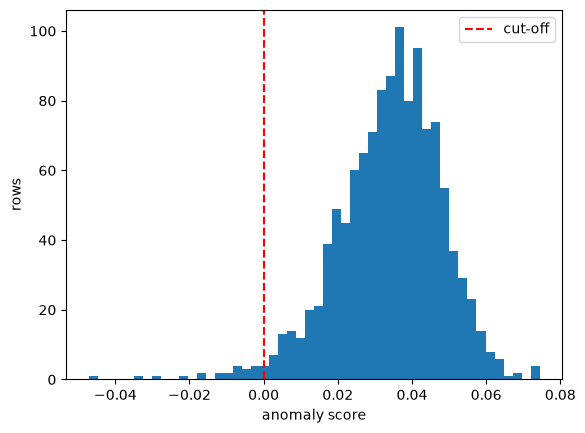

(1187, 828) (1187, 828) (1187,)


In [ ]:
# Outlier detection

from sklearn.preprocessing import RobustScaler
from sklearn.ensemble import IsolationForest
import matplotlib.pyplot as plt

# scale with median/IQR so outliers don't distort the scaling
X_train_scaled = pd.DataFrame(RobustScaler().fit_transform(X_train_med),
                              index=X_train_med.index, columns=X_train_med.columns)

# flag ~2% of rows as outliers
iso = IsolationForest(contamination=0.02, random_state=0)
inlier = iso.fit_predict(X_train_scaled) == 1   # 1 = inlier, -1 = outlier
scores = iso.decision_function(X_train_scaled)  # lower = more anomalous

print("outliers found:", (~inlier).sum(), "of", len(inlier))

# score distribution: outliers should sit in a separate tail on the left
plt.hist(scores, bins=50)
plt.axvline(0, color="red", linestyle="--", label="cut-off")
plt.xlabel("anomaly score"); plt.ylabel("rows"); plt.legend()
plt.show()

# new tables without the outlier rows
X_train_in     = X_train[inlier]       # original values with NaNs (for the final kNN step)
X_train_med_in = X_train_med[inlier]   # median-filled (for feature selection)
y_train_in     = y_train[inlier]

print(X_train_in.shape, X_train_med_in.shape, y_train_in.shape)
